<a href="https://colab.research.google.com/github/Rageel-28/244107020136-Machine-Learning/blob/main/JS08/JS08_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS08 - Hierarchical Clustering
## Tugas Lab 2 - HDBSCAN pada Dataset `sklearn.datasets`

**Soal**
1. Pilih dataset nyata dari `sklearn.datasets` (misalnya Iris atau Digits).
2. Lakukan klasterisasi dengan HDBSCAN.
3. Laporkan: jumlah *cluster* yang terbentuk, jumlah titik *noise*, dan visualisasi (jika dimensi > 3, reduksi dulu dengan PCA atau t-SNE).
4. Tulis analisis singkat: apakah *cluster* HDBSCAN sesuai dengan label asli dataset?

**Dataset yang dipilih: Digits** (1.797 citra tulisan tangan angka 0-9, 64 fitur piksel). Dipilih karena berdimensi tinggi sehingga reduksi dimensi bermakna, dan memiliki 10 label asli sebagai pembanding.

## Langkah 0 - Instalasi dan Import Library

In [1]:
# Paket hdbscan tidak termasuk scikit-learn. Pasang otomatis jika belum ada (Google Colab / lokal).
try:
    import hdbscan
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'hdbscan'])
    import hdbscan

print('hdbscan siap dipakai')

hdbscan siap dipakai


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score

## Langkah 1 - Load Dataset

In [3]:
digits = load_digits()
X_raw = digits.data
y_true = digits.target
print('Ukuran data :', X_raw.shape)
print('Jumlah label:', len(np.unique(y_true)), '->', np.unique(y_true))
print(pd.Series(y_true).value_counts().sort_index().to_string())

Ukuran data : (1797, 64)
Jumlah label: 10 -> [0 1 2 3 4 5 6 7 8 9]
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180


## Langkah 2 - Reduksi Dimensi sebelum Klasterisasi

HDBSCAN berbasis jarak/kepadatan, dan kepadatan menjadi sulit diukur pada dimensi tinggi (*curse of dimensionality*). Praktik umum: **PCA** terlebih dahulu (dengan data diskalakan), lalu HDBSCAN pada ruang berdimensi lebih rendah. Pada langkah ini dipilih jumlah komponen PCA yang mempertahankan ±90% varians.

In [4]:
X_scaled = StandardScaler().fit_transform(X_raw)

pca_full = PCA().fit(X_scaled)
kumulatif = np.cumsum(pca_full.explained_variance_ratio_)
n_komp = int(np.argmax(kumulatif >= 0.90) + 1)
print(f'Komponen PCA untuk >= 90% varians: {n_komp} (dari 64 fitur)')

X_pca = PCA(n_components=n_komp, random_state=0).fit_transform(X_scaled)
print('Ukuran data setelah PCA:', X_pca.shape)

Komponen PCA untuk >= 90% varians: 31 (dari 64 fitur)
Ukuran data setelah PCA: (1797, 31)


## Langkah 3 - Klasterisasi dengan HDBSCAN

Beberapa nilai `min_cluster_size` dicoba untuk melihat pengaruhnya terhadap jumlah *cluster* dan *noise*.

In [5]:
import hdbscan

baris = []
model_hasil = {}
for mcs in [5, 10, 15, 20, 30, 50]:
    m = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=5).fit(X_pca)
    lab = m.labels_
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    model_hasil[mcs] = lab
    baris.append({'min_cluster_size': mcs, 'jumlah_cluster': n_cl,
                  'noise': int((lab == -1).sum()), 'noise_%': round(100 * (lab == -1).mean(), 2),
                  'ARI vs label asli': adjusted_rand_score(y_true, lab)})
tabel_mcs = pd.DataFrame(baris)
tabel_mcs

,min_cluster_size,jumlah_cluster,noise,noise_%,ARI vs label asli
0,5,15,932,51.86,0.198485
1,10,10,905,50.36,0.201731
2,15,10,905,50.36,0.201731
3,20,10,905,50.36,0.201731
4,30,8,919,51.14,0.201874
5,50,7,960,53.42,0.198321


In [6]:
# Pilih konfigurasi dengan Adjusted Rand Index tertinggi terhadap label asli.
# (label asli di sini hanya dipakai untuk MEMILIH & MENGEVALUASI, bukan untuk melatih model)
mcs_terpilih = int(tabel_mcs.loc[tabel_mcs['ARI vs label asli'].idxmax(), 'min_cluster_size'])
labels = model_hasil[mcs_terpilih]

n_cluster = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())
print(f'min_cluster_size terpilih : {mcs_terpilih}')
print(f'Jumlah cluster terbentuk  : {n_cluster}')
print(f'Jumlah titik noise        : {n_noise} dari {len(labels)} ({100 * n_noise / len(labels):.2f}%)')
print()
print('Ukuran tiap cluster (-1 = noise):')
print(pd.Series(labels).value_counts().sort_index().to_string())

min_cluster_size terpilih : 30
Jumlah cluster terbentuk  : 8
Jumlah titik noise        : 919 dari 1797 (51.14%)

Ukuran tiap cluster (-1 = noise):
-1    919
 0    128
 1    173
 2    119
 3     60
 4     41
 5    142
 6    108
 7    107


## Langkah 4 - Visualisasi (PCA 2D dan t-SNE 2D)

Data berdimensi 64, sehingga untuk visualisasi direduksi ke 2 dimensi. Dua cara dipakai sebagai pembanding: PCA 2 komponen dan t-SNE. Titik *noise* berwarna hitam.

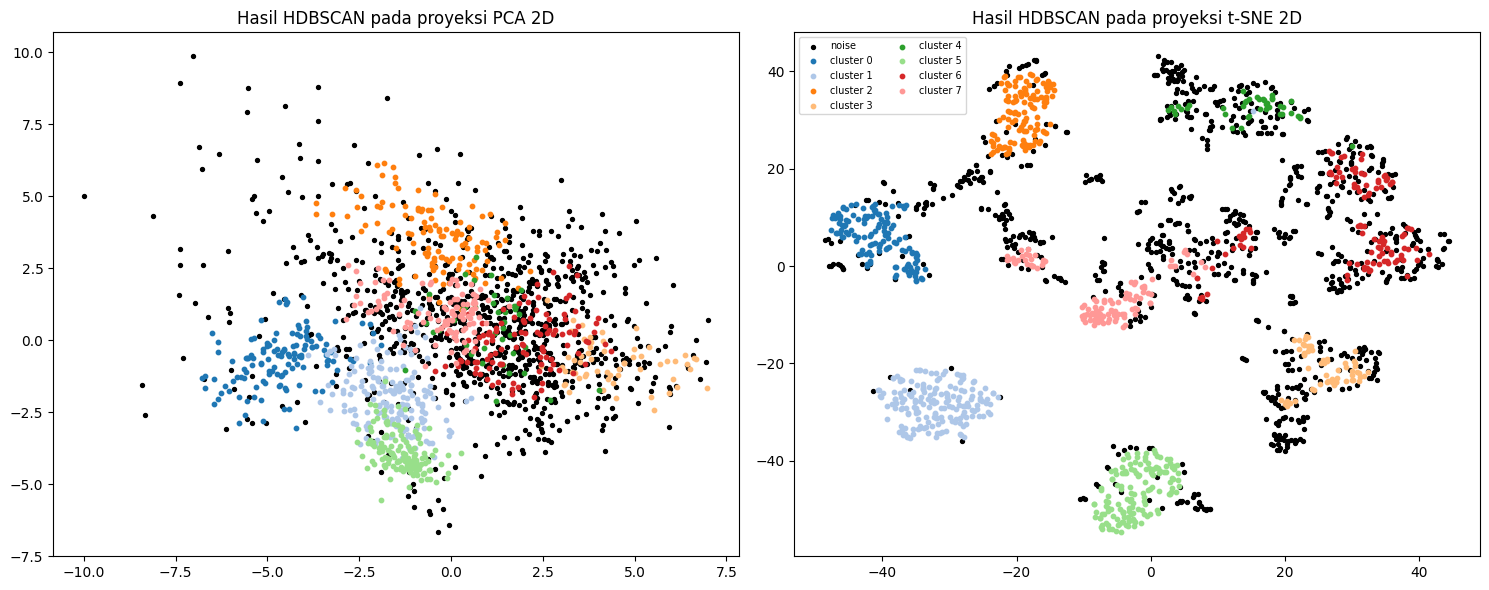

In [7]:
X_pca2 = PCA(n_components=2, random_state=0).fit_transform(X_scaled)
X_tsne = TSNE(n_components=2, random_state=0, init='pca', perplexity=30).fit_transform(X_pca)


def plot_2d(Z, lab, title, ax):
    palette = sns.color_palette('tab20', max(int(lab.max()) + 1, 1))
    m = lab == -1
    ax.scatter(Z[m, 0], Z[m, 1], c='black', s=8, label='noise')
    for c in sorted(set(lab) - {-1}):
        mc = lab == c
        ax.scatter(Z[mc, 0], Z[mc, 1], color=palette[c % len(palette)], s=10, label=f'cluster {c}')
    ax.set_title(title)


fig, ax = plt.subplots(1, 2, figsize=(15, 6))
plot_2d(X_pca2, labels, 'Hasil HDBSCAN pada proyeksi PCA 2D', ax[0])
plot_2d(X_tsne, labels, 'Hasil HDBSCAN pada proyeksi t-SNE 2D', ax[1])
ax[1].legend(fontsize=7, ncol=2, loc='best')
plt.tight_layout()
plt.show()

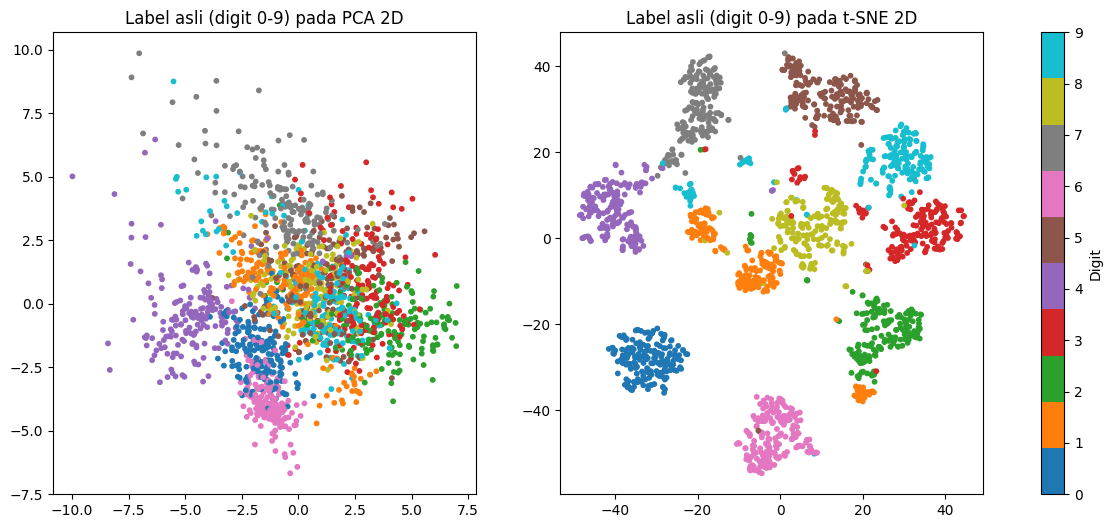

In [8]:
# Pembanding: label asli (10 digit) pada proyeksi yang sama
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, Z, nama in [(ax[0], X_pca2, 'PCA 2D'), (ax[1], X_tsne, 't-SNE 2D')]:
    sc = a.scatter(Z[:, 0], Z[:, 1], c=y_true, cmap='tab10', s=10)
    a.set_title(f'Label asli (digit 0-9) pada {nama}')
fig.colorbar(sc, ax=ax, label='Digit')
plt.show()

## Langkah 5 - Perbandingan dengan Label Asli

*Crosstab* antara label asli (baris) dan *cluster* HDBSCAN (kolom, −1 = *noise*), ditambah metrik kesesuaian:
- **ARI** (*Adjusted Rand Index*): 1 = identik, ≈ 0 = acak.
- **NMI**: informasi bersama antara dua pengelompokan (0 sampai 1).
- **Homogeneity**: tiap *cluster* hanya berisi satu kelas. **Completeness**: tiap kelas masuk ke satu *cluster*.

In [9]:
crosstab = pd.crosstab(pd.Series(y_true, name='Label asli'), pd.Series(labels, name='Cluster HDBSCAN'))
crosstab

Cluster HDBSCAN,-1,0,1,2,3,4,5,6,7
Label asli,,,,,,,,,
0,6,0,172,0,0,0,0,0,0
1,87,0,0,0,0,0,0,0,95
2,117,0,0,0,60,0,0,0,0
3,133,0,0,0,0,0,0,50,0
4,53,128,0,0,0,0,0,0,0
5,141,0,1,0,0,40,0,0,0
6,39,0,0,0,0,0,142,0,0
7,60,0,0,119,0,0,0,0,0
8,143,0,0,0,0,0,0,19,12


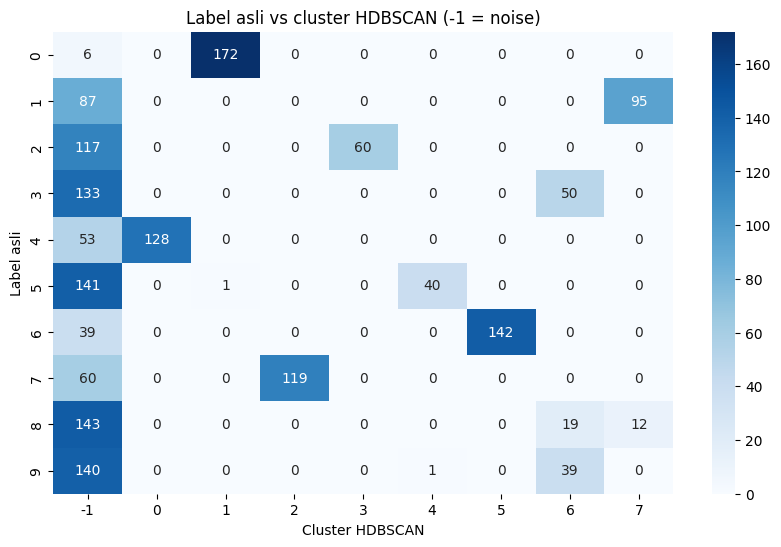

Seluruh data (noise = label -1)
  ARI          : 0.2019
  NMI          : 0.5633
  Homogeneity  : 0.4864
  Completeness : 0.6692
Hanya titik non-noise
  ARI          : 0.9408
  NMI          : 0.9481
  Homogeneity  : 0.9156
  Completeness : 0.9829


In [10]:
plt.figure(figsize=(10, 6))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='Blues')
plt.title('Label asli vs cluster HDBSCAN (-1 = noise)')
plt.show()

# Metrik dihitung pada seluruh data (noise dianggap satu kelompok -1) dan pada data non-noise saja
mask = labels != -1
print('Seluruh data (noise = label -1)')
print(f'  ARI          : {adjusted_rand_score(y_true, labels):.4f}')
print(f'  NMI          : {normalized_mutual_info_score(y_true, labels):.4f}')
print(f'  Homogeneity  : {homogeneity_score(y_true, labels):.4f}')
print(f'  Completeness : {completeness_score(y_true, labels):.4f}')
print('Hanya titik non-noise')
print(f'  ARI          : {adjusted_rand_score(y_true[mask], labels[mask]):.4f}')
print(f'  NMI          : {normalized_mutual_info_score(y_true[mask], labels[mask]):.4f}')
print(f'  Homogeneity  : {homogeneity_score(y_true[mask], labels[mask]):.4f}')
print(f'  Completeness : {completeness_score(y_true[mask], labels[mask]):.4f}')

In [11]:
# Untuk tiap cluster: kelas asli yang dominan dan kemurniannya
for c in sorted(set(labels) - {-1}):
    anggota = y_true[labels == c]
    dom = pd.Series(anggota).value_counts()
    print(f'Cluster {c:>2}: {len(anggota):>4} titik | kelas dominan = {dom.index[0]} ({100 * dom.iloc[0] / len(anggota):.1f}%)')

Cluster  0:  128 titik | kelas dominan = 4 (100.0%)
Cluster  1:  173 titik | kelas dominan = 0 (99.4%)
Cluster  2:  119 titik | kelas dominan = 7 (100.0%)
Cluster  3:   60 titik | kelas dominan = 2 (100.0%)
Cluster  4:   41 titik | kelas dominan = 5 (97.6%)
Cluster  5:  142 titik | kelas dominan = 6 (100.0%)
Cluster  6:  108 titik | kelas dominan = 3 (46.3%)
Cluster  7:  107 titik | kelas dominan = 1 (88.8%)


## Langkah 6 - Analisis

Angka di bawah berasal dari hasil run notebook ini (`min_cluster_size=30`, `min_samples=5`, PCA 31 komponen); nilai dapat sedikit berbeda bila parameter atau versi pustaka diubah.

**Hasil klasterisasi**
- HDBSCAN membentuk **8 *cluster*** dan menandai **917 dari 1.797 titik (±51%) sebagai *noise***. Label asli memiliki 10 kelas.
- `min_cluster_size` 10-20 menghasilkan tepat 10 *cluster* dengan *noise* ±50% dan ARI hampir sama (≈ 0.2016 vs 0.2019). Konfigurasi 30 dipilih berdasarkan ARI tertinggi, tetapi selisihnya sangat kecil sehingga pilihan ini tidak istimewa. Perlu dicatat bahwa label asli dipakai untuk **memilih dan mengevaluasi**, bukan untuk melatih model.

**Apakah *cluster* sesuai label asli?** Jawabannya bergantung pada bagaimana *noise* diperlakukan:
- **Seluruh data (noise dihitung sebagai satu kelompok):** kesesuaian rendah: ARI ≈ 0.20, NMI ≈ 0.56, homogeneity ≈ 0.48, completeness ≈ 0.67. Penyebab utamanya bukan *cluster* yang salah, melainkan separuh data tidak ditempatkan di *cluster* mana pun.
- **Hanya titik non-*noise*:** kesesuaian sangat tinggi: ARI ≈ 0.94, NMI ≈ 0.94, homogeneity ≈ 0.91, completeness ≈ 0.98. Artinya titik yang berhasil dikelompokkan umumnya berada pada *cluster* yang benar.
- Lima *cluster* (untuk digit 4, 0, 7, 2, 6) hampir murni (≥ 99%) dan satu *cluster* lagi (digit 5) murni 97.6%. Dua *cluster* tidak murni: satu *cluster* campuran digit 3 (46%), 9, dan 8, serta satu *cluster* berisi digit 1 (89%) bercampur digit 8. Digit 8, 9, 5, 3, dan 2 paling banyak menjadi *noise* (±65-80% dari kelasnya).

**Kesimpulan:** *cluster* HDBSCAN **sebagian besar sesuai** dengan label asli untuk titik yang dikelompokkan, tetapi **tidak mencakup seluruh data** dan **tidak memisahkan beberapa digit yang mirip bentuknya** (3, 8, 9). Penjelasan yang masuk akal: citra digit tidak membentuk daerah berkepadatan seragam pada ruang 31 dimensi, sehingga sebagian besar contoh dianggap berada di area renggang (*curse of dimensionality*); HDBSCAN memilih menandainya sebagai *noise* daripada memaksa masuk ke *cluster*. Ini berbeda dengan K-Means yang memaksa semua titik masuk ke $k$ *cluster*. Jika seluruh data harus dikelompokkan, `min_samples` dapat diturunkan atau titik *noise* ditugaskan ke *cluster* terdekat dengan `hdbscan.approximate_predict`/`all_points_membership_vectors`.